In [97]:
#%pip install contextily pyarrow -q

Note: you may need to restart the kernel to use updated packages.


In [10]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import contextily as cx

In [55]:
berk_parcels = gpd.read_parquet("../data/processed/berk_parcels_sb79tiers_zones.parquet")

In [56]:
#ensure projected to crs in feet
#set to 2227: NAD83 / California zone 3 (US survey foot)
berk_parcels = berk_parcels.to_crs(epsg=2227)

#create a column with the square feet of each parcel
berk_parcels["sqft"] = berk_parcels.area

In [63]:
first_letter_map = {
    "R": "Residential",
    "E": "Residential", #Environmental Residential
    "C": "Commercial",
    "S": "Special",
    "U": "Unclassified", 
}

# exclude institutional land (UC Berkeley, City of Berekeley, Parks, BART ROW) because it is not subject to local zoning.
    # public/exempt codes (0300, 0400, 0500) and UC 94720 ZIP
# keep R-BMU zoned parcels even though they are institutional land
berk_parcels["use_code_str"] = berk_parcels["use_code"].astype(str)
excluded_institutional = (berk_parcels["use_code"].isin(['0300', '0400', '0500']) | berk_parcels["situs_addre"].str.contains("94720", na=False)
                          ) & (berk_parcels["zoning"] != "R-BMU")

berk_parcels["base_zoning_type"] = berk_parcels["zoning"].str[0].map(first_letter_map)

sb79_eligible_mask = (
    berk_parcels["base_zoning_type"].isin(["Residential", "Commercial"])
    & ~excluded_institutional
)

# assign each SB79 tier to a 6 point scale
sb79_rank = {
    "Tier 2 - Half Mile": 3,
    "Tier 2 - Quarter Mile": 4,
    "Tier 1 - Half Mile": 4,
    "Tier 2 - 200ft": 5,
    "Tier 1 - Quarter Mile": 5,
    "Tier 1 - 200ft": 6,
}

# assign each zoning type to a 6 point scale based on density compared to SB79's tiers
berk_rank= {
    "ES-R": 1, "R-1": 1, "R-1H": 1, "R-1A": 1, "R-2": 1, "R-2H": 1,
    "R-2A": 2, "R-2AH": 2, "R-3": 2, "R-3H": 2,
    "R-4": 3, "R-4H": 3, "R-5H": 3, "R-S": 3, "R-SH": 3,
    "R-BMU": 5, "R-SMU": 5,
}

# assign each parcel to a rank scale based on its zoning and SB79 tier
berk_parcels.loc[sb79_eligible_mask, "sb79_scale"] = berk_parcels.loc[sb79_eligible_mask, "tier_zone_label"].map(sb79_rank)
berk_parcels.loc[sb79_eligible_mask, "berk_scale"] = berk_parcels.loc[sb79_eligible_mask, "zoning"].map(berk_rank)

berk_parcels["scale_change"] = berk_parcels["sb79_scale"] - berk_parcels["berk_scale"]

In [64]:
#aggregate based on parcel count and land area
sb79_scale_summary_df = berk_parcels.groupby('sb79_scale', dropna=False).agg(
    parcel_count=('sb79_scale', 'size'),
    total_sqft=('sqft', 'sum')
).reset_index()

#percentages relative to the citywide total
total_parcels = len(berk_parcels)
total_land = berk_parcels['sqft'].sum()

sb79_scale_summary_df['parcel_pct'] = (sb79_scale_summary_df['parcel_count'] / total_parcels * 100).round(2)
sb79_scale_summary_df['land_pct'] = (sb79_scale_summary_df['total_sqft'] / total_land * 100).round(2)

#clean display
sb79_scale_summary_df = sb79_scale_summary_df.sort_values(by='sb79_scale', na_position='last')
sb79_scale_summary_df

,sb79_scale,parcel_count,total_sqft,parcel_pct,land_pct
0,3.0,1332,9.594320e+06,14.29,9.90
1,4.0,5915,4.797231e+07,63.48,49.50
2,5.0,1853,1.111214e+07,19.89,11.47
3,6.0,28,4.854818e+05,0.30,0.50
4,NaN,190,2.774234e+07,2.04,28.63


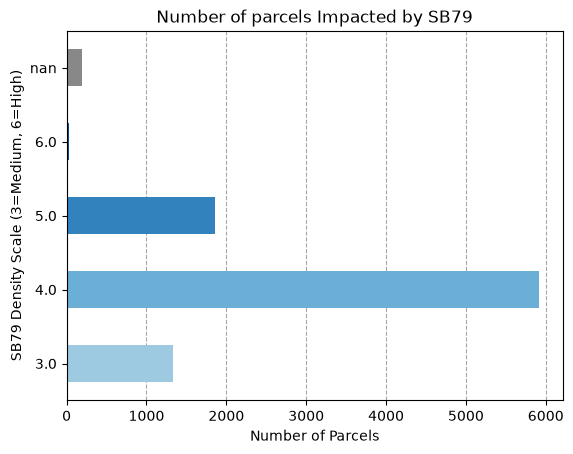

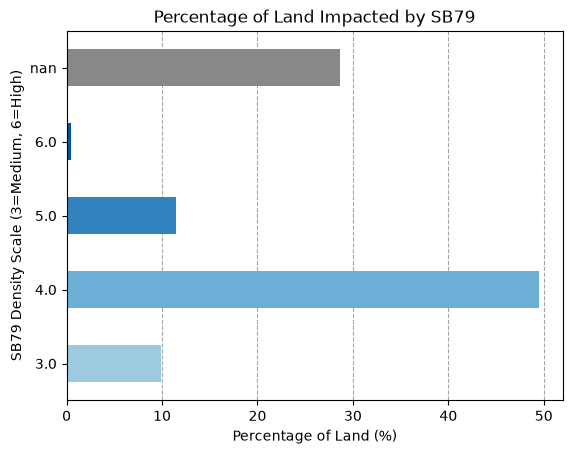

In [78]:
colors = {
    1: "#eff3ff",  #light blue
    2: "#c6dbef",
    3: "#9ecae1",
    4: "#6baed6",
    5: "#3182bd",
    6: "#08519c"   #dark blue
}

bar_colors = sb79_scale_summary_df['sb79_scale'].map(colors).fillna('#888888')

#plot parcel counts
sb79_parcel_chart = sb79_scale_summary_df.plot.barh(
    x='sb79_scale',
    y='parcel_count',
    color=bar_colors,
    legend=False,
    title='Number of parcels Impacted by SB79',
    ylabel="SB79 Density Scale (3=Medium, 6=High)",
    xlabel="Number of Parcels"
)

#plot the percentage of land
sb79_land_chart = sb79_scale_summary_df.plot.barh(
    x='sb79_scale',
    y='land_pct',
    color=bar_colors,
    legend=False,
    title='Percentage of Land Impacted by SB79',
    ylabel="SB79 Density Scale (3=Medium, 6=High)",
    xlabel="Percentage of Land (%)"
)

sb79_parcel_chart.set_axisbelow(True)
sb79_parcel_chart.grid(axis='x', linestyle='--', alpha=0.7, color='gray')
sb79_land_chart.set_axisbelow(True)
sb79_land_chart.grid(axis='x', linestyle='--', alpha=0.7, color='gray')

In [ ]:
#sb79_parcel_chart.get_figure(
#).savefig("../visualizations/berk_sb79_parcel_count_chart.jpg", dpi=300, bbox_inches="tight")
#sb79_land_chart.get_figure(
#).savefig("../visualizations/berk_sb79_land_pct_chart.jpg", dpi=300, bbox_inches="tight")

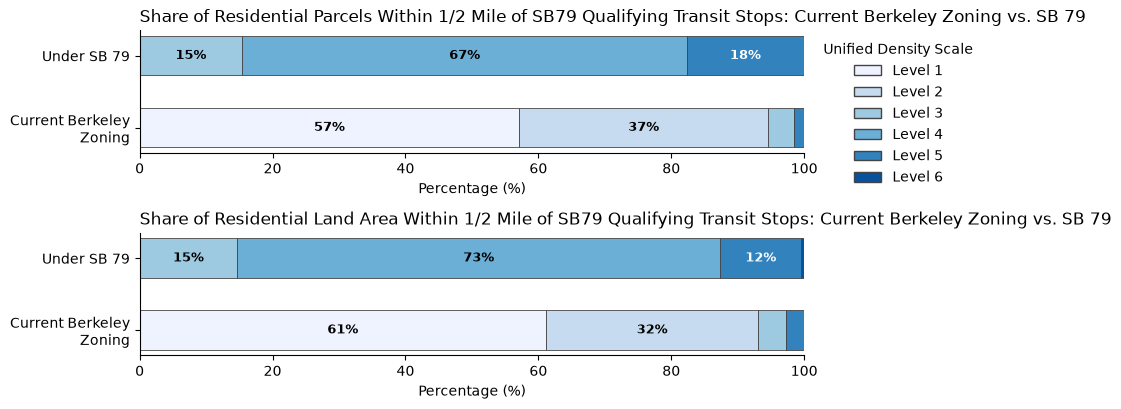

In [90]:
# 1. Filter to your scored residential parcels
# (Adjust column names here if yours are named berk_rank_6pt / sb79_rank_6pt / area_sqft)
res_df = berk_parcels.dropna(subset=["berk_scale", "sb79_scale"]).copy()

# 2. Build comp_df across all 6 unified density levels
ranks = pd.Index([1, 2, 3, 4, 5, 6], name="scale")
total_land = res_df["sqft"].sum()

comp_df = pd.DataFrame({
    "berk_parcels": res_df.groupby("berk_scale").size().reindex(ranks, fill_value=0),
    "sb79_parcels": res_df.groupby("sb79_scale").size().reindex(ranks, fill_value=0),
    "berk_land_pct": (res_df.groupby("berk_scale")["sqft"].sum() / total_land * 100).reindex(ranks, fill_value=0),
    "sb79_land_pct": (res_df.groupby("sb79_scale")["sqft"].sum() / total_land * 100).reindex(ranks, fill_value=0),
})

# 3. Plot the 100% stacked horizontal comparison chart
colors = {
    1: "#eff3ff",  # light blue
    2: "#c6dbef",
    3: "#9ecae1",
    4: "#6baed6",
    5: "#3182bd",
    6: "#08519c",  # dark blue
}

fig, (parcel_comp_chart, land_comp_chart) = plt.subplots(2, 1, figsize=(10, 4.2))

for ax, cols, title in [
    (parcel_comp_chart, ["berk_parcels", "sb79_parcels"], "Share of Residential Parcels Within 1/2 Mile of SB79 Qualifying Transit Stops: Current Berkeley Zoning vs. SB 79"),
    (land_comp_chart, ["berk_land_pct", "sb79_land_pct"], "Share of Residential Land Area Within 1/2 Mile of SB79 Qualifying Transit Stops: Current Berkeley Zoning vs. SB 79"),
]:
    sub = comp_df[cols].T
    sub_pct = sub.div(sub.sum(axis=1), axis=0) * 100
    sub_pct.index = ["Current Berkeley\nZoning", "Under SB 79"]
    left = pd.Series(0.0, index=sub_pct.index)

    for r in comp_df.index:
        ax.barh(sub_pct.index, sub_pct[r], left=left, color=colors[r], edgecolor="#444444", linewidth=0.6, height=0.55)
        for idx_name, val in sub_pct[r].items():
            if val >= 6:
                txt_color = "white" if r >= 5 else "black"
                ax.text(left[idx_name] + val / 2, idx_name, f"{val:.0f}%", va="center", ha="center", fontsize=9, color=txt_color, fontweight="bold")
        left += sub_pct[r]

    ax.set_xlim(0, 100)
    ax.set_xlabel("Percentage (%)")
    ax.set_title(title, loc="left")
    ax.spines[["top", "right"]].set_visible(False)

handles = [mpatches.Patch(facecolor=colors[r], edgecolor="#444444", label=f"Level {r}") for r in comp_df.index]
parcel_comp_chart.legend(handles=handles, title="Unified Density Scale", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)

plt.tight_layout()
plt.show()

In [ ]:
#parcel_comp_chart.get_figure(
#).savefig("../visualizations/berk_comp_parcel_count_chart.png", dpi=300, bbox_inches="tight")
#land_comp_chart.get_figure(
#).savefig("../visualizations/berk_comp_land_pct_chart.png", dpi=300, bbox_inches="tight")

In [66]:
#set to geographic coordinate system WGS 84 (ESPG 4326) which uses latitude and longitude
berk_parcels_4326 = berk_parcels.to_crs(epsg=4326)

#map the parcels in Oakland assigned to each scale
sb79_scale_map = berk_parcels_4326.explore(
    column='sb79_scale',
    categorical=True,
    cmap='Blues',
    legend_kwds={'caption': 'SB79 Scale (1-6)'}
)

In [67]:
sb79_scale_map.save("../visualizations/berk_sb79_scale_map.html")

In [68]:
berk_parcels = berk_parcels[['apn', 'use_code', 'situs_addre', 'geometry', 'tier_zone_label',
       'zoning', 'zoning_description', 'zoning_type', 'zoning_subtype', 'max_building_height_ft', 
       'max_density_du_per_acre', 'sqft', 'base_zoning_type', 'sb79_scale', 'berk_scale', 'scale_change']
       ].copy()

In [73]:
# assign each parcel to the amount that it increased, and if the original density was higher, then it's assigned to zero (i.e., no increase)
berk_parcels['net_scale_increase'] = berk_parcels['scale_change']
berk_parcels.loc[berk_parcels['net_scale_increase'] < 0, 'net_scale_increase'] = 0

# create a boolean column to indicate whether the parcel's density increased or not or NaN if not relavant (i.e., not residential)
berk_parcels['density_increases'] = pd.Series(dtype='object')
berk_parcels.loc[berk_parcels['net_scale_increase'] > 0, 'density_increases'] = True
berk_parcels.loc[berk_parcels['net_scale_increase'] == 0, 'density_increases'] = False

# check if the parcel was assigned an SB79 scale (i.e., was zoned commercial)
berk_parcels['became_residential'] = (
    berk_parcels['sb79_scale'].notna() &
    (berk_parcels['berk_scale'].isna())
)

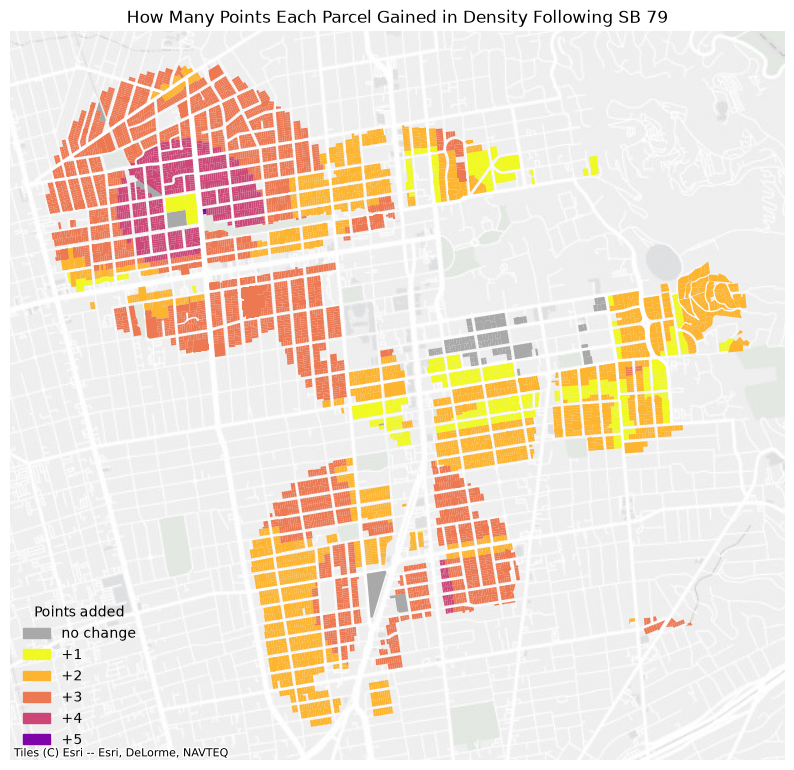

In [ ]:
# Finding how much SB79 changes the residential density of Berkeley

berk_3857 = berk_parcels.to_crs(epsg=3857)  # reproject to Web Mercator (EPSG:3857) for compatibility with basemap tiles

fig, ax = plt.subplots(figsize=(10, 10))

change_colors = {
    0: "#A9A9A9",
    1: "#f0f921",
    2: "#fdb42f",
    3: "#ed7953",
    4: "#cc4778",
    5: "#7e03a8", 
    6: "#0d0887",  
}

for change, color in change_colors.items():
    layer = berk_3857[berk_3857["net_scale_increase"] == change]
    if len(layer) > 0:
        layer.plot(ax=ax, color=color, linewidth=0, zorder=2)  # zorder=2 ensures parcels are drawn above the basemap

cx.add_basemap(
    ax,
    source=cx.providers.Esri.WorldGrayCanvas,
    zorder=1  # Draw basemap BELOW parcels
)

handles = [
    mpatches.Patch(color=c, label=("no change" if k == 0 else f"+{k}"))
    for k, c in change_colors.items()
    if (berk_3857["net_scale_increase"] == k).any()
]

ax.legend(handles=handles, title="Points added", loc="lower left", frameon=False)
ax.set_title("How Many Points Each Parcel Gained in Density Following SB 79", loc="center")
ax.set_axis_off()

plt.savefig("../visualizations/berk_scale_change_map.png", dpi=300, bbox_inches="tight")
plt.show()

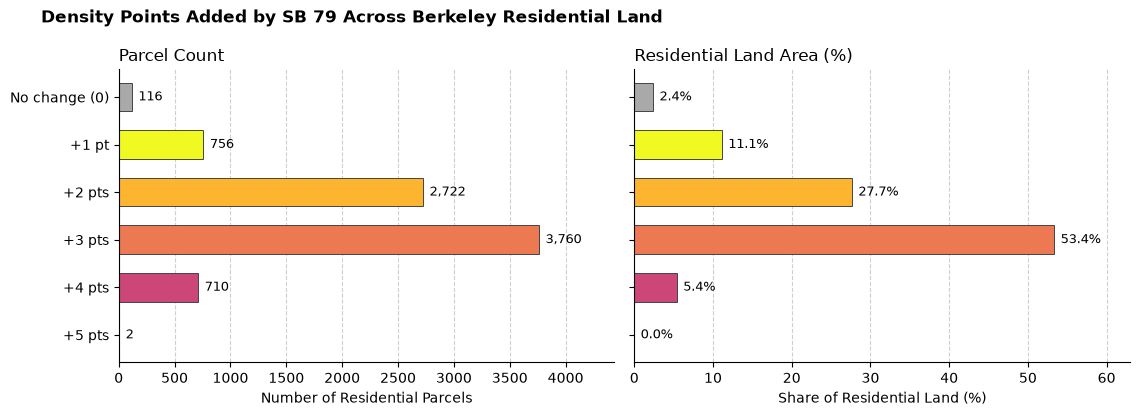

In [94]:
# 1. Summarize parcel counts and land area share by net_scale_increase
res_df = berk_parcels.dropna(subset=["net_scale_increase"]).copy()
res_df["net_scale_increase"] = res_df["net_scale_increase"].astype(int)

summary = (
    res_df.groupby("net_scale_increase")
    .agg(
        parcel_count=("apn", "count"),
        land_sqft=("sqft", "sum"),
    )
    .sort_index()
)
summary["land_pct"] = summary["land_sqft"] / summary["land_sqft"].sum() * 100

# 2. Reuse the exact map palette
change_colors = {
    0: "#A9A9A9",  # no change
    1: "#f0f921",  # +1
    2: "#fdb42f",  # +2
    3: "#ed7953",  # +3
    4: "#cc4778",  # +4
    5: "#7e03a8",  # +5
    6: "#0d0887",  # +6
}

labels = ["No change (0)" if k == 0 else f"+{k} pt{'s' if k > 1 else ''}" for k in summary.index]
bar_colors = [change_colors[k] for k in summary.index]
y = list(range(len(summary)))

# 3. Plot side-by-side horizontal bars
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)

bars1 = ax1.barh(y, summary["parcel_count"], color=bar_colors, edgecolor="#444444", linewidth=0.7, height=0.6)
ax1.set_yticks(y)
ax1.set_yticklabels(labels, fontsize=10)
ax1.invert_yaxis()
ax1.set_xlabel("Number of Residential Parcels")
ax1.set_title("Parcel Count", loc="left")
ax1.set_xlim(0, summary["parcel_count"].max() * 1.18)
ax1.set_axisbelow(True)
ax1.grid(axis="x", linestyle="--", alpha=0.6)
ax1.spines[["top", "right"]].set_visible(False)

for bar, cnt in zip(bars1, summary["parcel_count"]):
    ax1.text(cnt + 60, bar.get_y() + bar.get_height() / 2, f"{cnt:,}", va="center", ha="left", fontsize=9.5)

bars2 = ax2.barh(y, summary["land_pct"], color=bar_colors, edgecolor="#444444", linewidth=0.7, height=0.6)
ax2.set_xlabel("Share of Residential Land (%)")
ax2.set_title("Residential Land Area (%)", loc="left")
ax2.set_xlim(0, summary["land_pct"].max() * 1.18)
ax2.set_axisbelow(True)
ax2.grid(axis="x", linestyle="--", alpha=0.6)
ax2.spines[["top", "right"]].set_visible(False)

for bar, pct in zip(bars2, summary["land_pct"]):
    ax2.text(pct + 0.8, bar.get_y() + bar.get_height() / 2, f"{pct:.1f}%", va="center", ha="left", fontsize=9.5)

fig.suptitle("Density Points Added by SB 79 Across Berkeley Residential Land", x=0.04, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("../visualizations/berk_scale_increase_chart.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
berk_parcels.to_parquet("../data/processed/berk_parcels.parquet")